# CareerCompass AI

## An Intelligent AI Career Guidance Platform

### AI-Powered Resume Analysis and Career Recommendation System

**Developed By:** Anushka Gupta

---

### Project Overview

CareerCompass AI is an AI-powered career guidance platform that analyzes resumes and provides personalized career recommendations. The system extracts information from resumes, identifies technical skills, analyzes skill gaps, recommends suitable career roles, generates personalized learning roadmaps, and offers AI-assisted interview preparation.

### Technologies Used

- Python
- Streamlit
- Pandas
- NumPy
- Scikit-learn
- spaCy
- PyMuPDF
- pdfplumber
- Plotly
- Git & GitHub

# Module 1: Resume Intelligence

## Step 1: Install Required Libraries

### Objective

Install all the Python libraries required for resume parsing, Natural Language Processing (NLP), PDF processing, and web application development.

### Libraries Used

- Streamlit
- PyMuPDF
- pdfplumber
- spaCy

In [1]:
!pip -q install streamlit
!pip -q install pymupdf
!pip -q install pdfplumber
!pip -q install spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 42.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Step 2: Import Required Libraries

### Objective

Import all the required Python libraries for resume parsing, PDF processing, Natural Language Processing (NLP), and data manipulation.

### Libraries

- Pandas
- NumPy
- re
- PyMuPDF
- pdfplumber
- spaCy

In [2]:
import pandas as pd
import numpy as np
import re

import fitz
import pdfplumber

import spacy

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 3: Upload Resume

### Objective

Upload the candidate's resume in PDF format. The uploaded resume will be processed by the CareerCompass AI system to extract personal details, technical skills, education, experience, and other relevant information.

### Input

- Resume (PDF)

### Output

- Uploaded PDF ready for processing

In [3]:
from google.colab import files

uploaded = files.upload()

Saving 20001721.pdf to 20001721 (1).pdf


## Step 4: Read the Uploaded Resume

### Objective

Open the uploaded PDF file and verify that it has been loaded successfully. This step ensures that the resume is accessible before extracting any information.

### Output

- PDF loaded successfully
- Total number of pages

In [4]:
import fitz

pdf_file = list(uploaded.keys())[0]

doc = fitz.open(pdf_file)

print("PDF loaded successfully!")
print("Number of Pages:", len(doc))

PDF loaded successfully!
Number of Pages: 2


In [5]:
for i in range(len(doc)):
    print(f"Page {i+1}")
    print(doc[i].get_text()[:100])
    print("-" * 40)

Page 1
INFORMATION TECHNOLOGY STUDENT
Career Overview
Results-driven Database Administrator with extensive 
----------------------------------------
Page 2
Skills
Microsoft Word, Excel, Access, SQL Server, VBA, Visual Studio

----------------------------------------


## Step 5: Extract Text from Resume

### Objective

Extract all textual content from the uploaded resume. The extracted text will be used in the next stages for information extraction, skill detection, resume summarization, and AI-powered career recommendations.

### Output

- Complete resume text

In [6]:
text = ""

for page in doc:
    text += page.get_text()

print(text)

INFORMATION TECHNOLOGY STUDENT
Career Overview
Results-driven Database Administrator with extensive education in programming, relational database management and computer technology
maintenance.
Qualifications
Database servers
Structured query language (SQL) expert
Programming and design skills
Document management
Strong collaborative skills
Strong analytical skills
Customer needs assessment
Excellent problem solving skills
Technical Skills
Skills
Experience
Total
Years
Last
Used
Windows, Unix, Linux, Mac OSX, VMWare, HTTP/Apache, DNS/BIND, SSH, SNMP, DNS, DHCP,
FTP
Intermediate 2
May 2016
Accomplishments
Customer Service
Handled customers effectively by identifying needs, quickly gaining trust, approaching complex situations and resolving problems to
maximize efficiency.
Data Preparation
Prepared chain of custody packets for title sale reviews of procedures and fees/services justification.
Administration
Performed administration tasks such as filing, developing spreadsheets, faxing rep

## Step 6: Extract Candidate Name

### Objective

Extract the candidate's full name from the resume automatically using Natural Language Processing (NLP). This information will be displayed in the CareerCompass AI dashboard and used throughout the application.

### Output

- Candidate Name

In [7]:
import re

name = None

for line in text.split("\n"):
    line = line.strip()

    if re.fullmatch(r"[A-Z ]{5,}", line):
        if line not in [
            "EDUCATION",
            "KEY SKILLS",
            "CERTIFICATIONS",
            "PROJECTS",
            "TECHNICAL SKILLS",
            "PROFESSIONAL SUMMARY"
        ]:
            name = line
            break

print("Candidate Name:", name)

Candidate Name: INFORMATION TECHNOLOGY STUDENT


## Step 7: Extract Email Address

### Objective

Extract the candidate's email address from the resume using Regular Expressions (Regex).

### Output

- Candidate Email Address

In [8]:
import re

email = re.findall(
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
    text
)

print("Email:", email[0] if email else "Not Found")

Email: Not Found


## Step 8: Extract Phone Number

### Objective

Extract the candidate's phone number from the uploaded resume using Regular Expressions (Regex).

### Output

- Candidate Phone Number

In [9]:
import re

phone = re.findall(
    r"\+?\d[\d\s-]{8,15}\d",
    text
)

phone = [p for p in phone if "2023" not in p and "2027" not in p]

print("Phone Number:", phone[0] if phone else "Not Found")

Phone Number: Not Found


## Step 9: Extract Technical Skills

### Objective

Extract the candidate's technical skills from the resume by comparing the resume text with a predefined list of AI/ML, Data Science, and Programming skills.

### Output

- List of Detected Technical Skills

In [10]:
skills_db = [
    "Python",
    "SQL",
    "NumPy",
    "Pandas",
    "Scikit-learn",
    "Machine Learning",
    "Deep Learning",
    "Data Analysis",
    "Data Visualization",
    "Feature Engineering",
    "Data Preprocessing",
    "EDA",
    "Git",
    "GitHub",
    "Streamlit",
    "TensorFlow",
    "Keras",
    "Matplotlib",
    "Seaborn"
]

found_skills = []

for skill in skills_db:
    if skill.lower() in text.lower():
        found_skills.append(skill)

print("Technical Skills:")
for skill in found_skills:
    print("-", skill)

Technical Skills:
- SQL


## Step 10: Extract Education

### Objective

Extract the candidate's educational qualifications from the resume by identifying common education-related keywords.

### Output

- Education Details

In [11]:
# Step 10: Extract Education Details

education_keywords = [
    "Bachelor", "B.Tech", "B.E", "B.Sc", "BCA",
    "M.Tech", "M.E", "M.Sc", "MCA",
    "MBA", "M.S", "PhD", "University",
    "College", "Institute"
]

education = []

lines = [line.strip() for line in text.split("\n") if line.strip()]

for line in lines:
    line_lower = line.lower()

    if any(keyword.lower() in line_lower for keyword in education_keywords):
        if line not in education:
            education.append(line)

print("Education Details:\n")

if education:
    for edu in education:
        print("-", edu)
else:
    print("No education details found.")

Education Details:

- SAN DIEGO STATE UNIVERSITY 2006 Bachelor of Arts : English City , State , United States


## Step 11: Extract Projects (Improved)

### Objective

Extract the complete Projects section from the resume by identifying the PROJECTS heading and collecting all project details until the next section starts.

### Output

- Project Titles
- Project Descriptions

In [12]:
projects = []

capture = False

stop_headings = [
    "CERTIFICATIONS",
    "ADDITIONAL INFORMATION",
    "EDUCATION",
    "EXPERIENCE",
    "TECHNICAL SKILLS",
    "PROFESSIONAL SUMMARY",
    "KEY SKILLS",
    "2023 - 2027"
]

for line in text.split("\n"):

    line = line.strip()

    if "PROJECTS" == line.upper():
        capture = True
        continue

    if capture:

        if line.upper() in stop_headings:
            break

        if line.startswith("2023"):
            break

        if line != "":
            projects.append(line)

print("Projects:\n")

for p in projects:
    print("-", p)

Projects:



In [13]:
# ==============================
# Certifications Extraction
# ==============================

certification_keywords = [
    "certification",
    "certified",
    "certificate",
    "certificates",
    "credential",
    "credentials",
    "license",
    "licensed"
]

certifications = []

# Split resume text into clean lines
lines = [
    line.strip()
    for line in text.split("\n")
    if line.strip()
]

# Extract certification-related lines
for line in lines:
    line_lower = line.lower()

    if (
        any(keyword in line_lower for keyword in certification_keywords)
        and line_lower not in ["certifications", "certification"]
        and not line_lower.startswith("tools:")
    ):
        if line not in certifications:
            certifications.append(line)

# Display results
print("Certifications:\n")

if certifications:
    for cert in certifications:
        print("-", cert)
else:
    print("No certifications found.")

Certifications:

No certifications found.


## Step 12: Extract Technical Skills

### Objective

Extract the candidate's technical skills from the resume by identifying the **KEY SKILLS** section and storing the skills in a Python list.

### Output

- Python
- SQL
- NumPy
- Pandas
- Scikit-learn
- Data Preprocessing
- Feature Engineering
- Exploratory Data Analysis (EDA)
- Model Evaluation
- Data Visualization

In [14]:
# Step 12: Extract Technical Skills

skills_db = [
    "Python",
    "SQL",
    "NumPy",
    "Pandas",
    "Scikit-learn",
    "Machine Learning",
    "Deep Learning",
    "Artificial Intelligence",
    "Data Science",
    "Data Analytics",
    "Data Preprocessing",
    "Feature Engineering",
    "Exploratory Data Analysis",
    "EDA",
    "Data Visualization",
    "Matplotlib",
    "Seaborn",
    "Plotly",
    "NLP",
    "Natural Language Processing",
    "LLM",
    "OpenAI API",
    "Streamlit",
    "TensorFlow",
    "PyTorch",
    "Keras",
    "Git",
    "GitHub"
]

skills = []

for skill in skills_db:
    if re.search(r'\b' + re.escape(skill) + r'\b', text, re.IGNORECASE):
        if skill not in skills:
            skills.append(skill)

print("Technical Skills:\n")

for skill in skills:
    print("-", skill)

print("\nTotal Skills:", len(skills))

Technical Skills:

- SQL

Total Skills: 1


## Step 13: Extract Certifications

### Objective

Extract the certifications listed in the resume by identifying the **CERTIFICATIONS** section.

### Output

- Python Mega Course – Udemy
- Python for Data Science & Machine Learning – Udemy
- Machine Learning A-Z – Udemy
- Microsoft 365 Essentials – Udemy

In [15]:
certification_keywords = [
    "certification",
    "certified",
    "certificate",
    "certificates",
    "credential",
    "credentials",
    "license",
    "licensed"
]

certifications = []

lines = [line.strip() for line in text.split("\n") if line.strip()]

for line in lines:
    line_lower = line.lower()

    if (
        any(keyword in line_lower for keyword in certification_keywords)
        and line_lower not in ["certifications", "certification"]
        and not line_lower.startswith("tools:")
    ):
        if line not in certifications:
            certifications.append(line)

print("Certifications:\n")

if certifications:
    for cert in certifications:
        print("-", cert)
else:
    print("No certifications found.")

Certifications:

No certifications found.


## Step 14: Extract Professional Summary

### Objective
Extract the candidate's professional summary from the resume.

### Output
- Professional Summary

In [16]:
# Step 14: Extract Professional Summary

summary = ""

# Common phrases that indicate the actual professional summary
summary_start_keywords = [
    "AI/ML and Data Science enthusiast",
    "AI/ML & Data Science enthusiast",
    "Data Science enthusiast",
    "Machine Learning enthusiast"
]

lines = [line.strip() for line in text.split("\n") if line.strip()]

for i, line in enumerate(lines):

    # Find the actual summary paragraph
    if any(keyword.lower() in line.lower() for keyword in summary_start_keywords):

        summary_lines = []

        for next_line in lines[i:]:
            upper_line = next_line.upper()

            # Stop when the next major section starts
            if upper_line in [
                "PROJECTS",
                "EXPERIENCE",
                "EDUCATION",
                "KEY SKILLS",
                "CERTIFICATIONS",
                "ADDITIONAL INFORMATION"
            ]:
                break

            # Ignore obvious headings/contact information
            if next_line.upper() not in [
                "PROFESSIONAL SUMMARY",
                "CERTIFICATIONS"
            ]:
                summary_lines.append(next_line)

        summary = " ".join(summary_lines)
        break

print("Professional Summary:\n")
print(summary if summary else "No professional summary found.")

Professional Summary:

No professional summary found.


## Step 15: Create Structured Resume Data

### Objective

Organize all the extracted information into a structured Python dictionary. This structured format enables CareerCompass AI to efficiently access candidate information for skill gap analysis, career recommendations, interview preparation, and dashboard visualization.

### Output

- Structured Resume Data

In [17]:
# Step 15: Create Structured Resume Data

resume_data = {
    "Name": name,
    "Email": email,
    "Phone": phone,
    "Education": education,
    "Skills": skills,
    "Projects": projects,
    "Certifications": certifications,
    "Professional Summary": summary
}

print("Structured Resume Data:\n")

for key, value in resume_data.items():
    print(f"{key}:")
    print(value)
    print("-" * 50)

Structured Resume Data:

Name:
INFORMATION TECHNOLOGY STUDENT
--------------------------------------------------
Email:
[]
--------------------------------------------------
Phone:
[]
--------------------------------------------------
Education:
['SAN DIEGO STATE UNIVERSITY 2006 Bachelor of Arts : English City , State , United States']
--------------------------------------------------
Skills:
['SQL']
--------------------------------------------------
Projects:
[]
--------------------------------------------------
Certifications:
[]
--------------------------------------------------
Professional Summary:

--------------------------------------------------


## Step 16: Convert Resume Data into DataFrame

### Objective

Convert the extracted resume information into a structured Pandas DataFrame for easier analysis, visualization, storage, and future AI-based career recommendations.

### Output

- Resume DataFrame

In [18]:
import pandas as pd

df = pd.DataFrame([resume_data])

print("Resume DataFrame Created Successfully!\n")

df

Resume DataFrame Created Successfully!



,Name,Email,Phone,Education,Skills,Projects,Certifications,Professional Summary
0,INFORMATION TECHNOLOGY STUDENT,[],[],[SAN DIEGO STATE UNIVERSITY 2006 Bachelor of A...,[SQL],[],[],


## Step 17: Save Resume Data to CSV

### Objective

Save the extracted resume information into a CSV file so it can be used later for dashboards, machine learning, or career recommendation systems.

### Output

- resume_data.csv

In [19]:
df.to_csv("resume_data.csv", index=False)

print("Resume data saved successfully as resume_data.csv")

Resume data saved successfully as resume_data.csv


In [20]:
from google.colab import files

files.download("resume_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 18: Skill Gap Analysis

In [21]:
# Step 18: Skill Gap Analysis

# Target skills for an AI/ML & Data Science career
target_skills = [
    "Python",
    "SQL",
    "NumPy",
    "Pandas",
    "Scikit-learn",
    "Machine Learning",
    "Deep Learning",
    "Data Preprocessing",
    "Feature Engineering",
    "Exploratory Data Analysis",
    "Data Visualization",
    "Matplotlib",
    "Seaborn",
    "Natural Language Processing",
    "TensorFlow",
    "PyTorch",
    "Git",
    "GitHub",
    "Streamlit"
]

# Normalize extracted skills
user_skills = {skill.lower().strip() for skill in skills}

# Find matched and missing skills
matched_skills = []
missing_skills = []

for skill in target_skills:
    if skill.lower() in user_skills:
        matched_skills.append(skill)
    else:
        missing_skills.append(skill)

# Calculate skill coverage
skill_coverage = (
    len(matched_skills) / len(target_skills) * 100
    if target_skills else 0
)

print("SKILL GAP ANALYSIS")
print("=" * 40)

print("\nMatched Skills:")
for skill in matched_skills:
    print("-", skill)

print("\nMissing / Recommended Skills:")
for skill in missing_skills:
    print("-", skill)

print(f"\nSkill Coverage: {skill_coverage:.1f}%")

SKILL GAP ANALYSIS

Matched Skills:
- SQL

Missing / Recommended Skills:
- Python
- NumPy
- Pandas
- Scikit-learn
- Machine Learning
- Deep Learning
- Data Preprocessing
- Feature Engineering
- Exploratory Data Analysis
- Data Visualization
- Matplotlib
- Seaborn
- Natural Language Processing
- TensorFlow
- PyTorch
- Git
- GitHub
- Streamlit

Skill Coverage: 5.3%


## Step 19: Career Recommendation

In [22]:
# Step 19: Career Recommendation

career_requirements = {
    "Data Scientist": [
        "Python",
        "SQL",
        "Pandas",
        "NumPy",
        "Scikit-learn",
        "Machine Learning",
        "Data Visualization",
        "Exploratory Data Analysis"
    ],

    "Machine Learning Engineer": [
        "Python",
        "NumPy",
        "Pandas",
        "Scikit-learn",
        "Machine Learning",
        "Feature Engineering",
        "Git",
        "GitHub"
    ],

    "AI / NLP Engineer": [
        "Python",
        "Machine Learning",
        "Natural Language Processing",
        "Deep Learning",
        "Scikit-learn"
    ],

    "Data Analyst": [
        "Python",
        "SQL",
        "Pandas",
        "NumPy",
        "Data Visualization",
        "Exploratory Data Analysis"
    ]
}

user_skill_set = {skill.lower().strip() for skill in skills}

career_scores = {}

for career, required_skills in career_requirements.items():

    matched = [
        skill for skill in required_skills
        if skill.lower() in user_skill_set
    ]

    score = (len(matched) / len(required_skills)) * 100

    career_scores[career] = {
        "score": score,
        "matched_skills": matched,
        "missing_skills": [
            skill for skill in required_skills
            if skill.lower() not in user_skill_set
        ]
    }

# Rank careers by matching percentage
ranked_careers = sorted(
    career_scores.items(),
    key=lambda x: x[1]["score"],
    reverse=True
)

print("CAREER RECOMMENDATIONS")
print("=" * 50)

for career, details in ranked_careers:
    print(f"\n{career}")
    print(f"Match Score: {details['score']:.1f}%")
    print("Matched Skills:", ", ".join(details["matched_skills"]))

    if details["missing_skills"]:
        print("Skills to Improve:", ", ".join(details["missing_skills"]))

# Best career recommendation
best_career = ranked_careers[0][0]

print("\n" + "=" * 50)
print("BEST CAREER RECOMMENDATION:", best_career)
print(f"Match Score: {ranked_careers[0][1]['score']:.1f}%")

CAREER RECOMMENDATIONS

Data Analyst
Match Score: 16.7%
Matched Skills: SQL
Skills to Improve: Python, Pandas, NumPy, Data Visualization, Exploratory Data Analysis

Data Scientist
Match Score: 12.5%
Matched Skills: SQL
Skills to Improve: Python, Pandas, NumPy, Scikit-learn, Machine Learning, Data Visualization, Exploratory Data Analysis

Machine Learning Engineer
Match Score: 0.0%
Matched Skills: 
Skills to Improve: Python, NumPy, Pandas, Scikit-learn, Machine Learning, Feature Engineering, Git, GitHub

AI / NLP Engineer
Match Score: 0.0%
Matched Skills: 
Skills to Improve: Python, Machine Learning, Natural Language Processing, Deep Learning, Scikit-learn

BEST CAREER RECOMMENDATION: Data Analyst
Match Score: 16.7%


## Step 20: Resume Score Analysis

### Objective

Evaluate the completeness and strength of the parsed resume using important profile components such as contact information, education, technical skills, projects, certifications, and professional summary.

### Output

- Resume Score out of 100
- Resume Quality Rating

In [23]:
# Step 20: Resume Score Analysis

# Component scores
skills_score = min(len(skills) / 10 * 30, 30)
projects_score = min(len(projects) / 3 * 25, 25)
certifications_score = min(len(certifications) / 3 * 15, 15)
education_score = 15 if education else 0
summary_score = 15 if summary and len(summary) >= 50 else 8 if summary else 0

# Final score
resume_score = (
    skills_score
    + projects_score
    + certifications_score
    + education_score
    + summary_score
)

resume_score = round(min(resume_score, 100), 1)

print("RESUME SCORE ANALYSIS")
print("=" * 40)

print(f"Skills Score: {skills_score:.1f}/30")
print(f"Projects Score: {projects_score:.1f}/25")
print(f"Certifications Score: {certifications_score:.1f}/15")
print(f"Education Score: {education_score:.1f}/15")
print(f"Summary Score: {summary_score:.1f}/15")

print("-" * 40)
print(f"FINAL RESUME SCORE: {resume_score}/100")

# Overall assessment
if resume_score >= 85:
    assessment = "Excellent"
elif resume_score >= 70:
    assessment = "Strong"
elif resume_score >= 55:
    assessment = "Moderate"
else:
    assessment = "Needs Improvement"

print(f"Overall Assessment: {assessment}")

RESUME SCORE ANALYSIS
Skills Score: 3.0/30
Projects Score: 0.0/25
Certifications Score: 0.0/15
Education Score: 15.0/15
Summary Score: 0.0/15
----------------------------------------
FINAL RESUME SCORE: 18.0/100
Overall Assessment: Needs Improvement


## Step 21: Learning Recommendations

### Objective

Recommend learning resources for the missing skills identified during skill gap analysis.

### Output

- Personalized Learning Recommendations

In [24]:
# Step 21: Learning Recommendations

learning_resources = {
    "Python": "Advanced Python + problem solving",
    "SQL": "SQL for Data Analytics",
    "NumPy": "NumPy for Data Science",
    "Pandas": "Pandas for Data Analysis",
    "Scikit-learn": "Scikit-learn and Machine Learning",
    "Machine Learning": "Machine Learning fundamentals and model building",
    "Deep Learning": "Deep Learning with TensorFlow/PyTorch",
    "Data Preprocessing": "Data Cleaning and Preprocessing",
    "Feature Engineering": "Feature Engineering techniques",
    "Exploratory Data Analysis": "Exploratory Data Analysis",
    "Data Visualization": "Data Visualization with Matplotlib/Seaborn",
    "Natural Language Processing": "NLP fundamentals",
    "TensorFlow": "TensorFlow for Deep Learning",
    "PyTorch": "PyTorch fundamentals",
    "Git": "Git version control",
    "GitHub": "GitHub and collaborative development",
    "Streamlit": "Streamlit app development"
}

learning_recommendations = []

for skill in missing_skills:
    if skill in learning_resources:
        learning_recommendations.append(
            learning_resources[skill]
        )

print("LEARNING RECOMMENDATIONS")
print("=" * 45)

if learning_recommendations:
    for i, recommendation in enumerate(
        learning_recommendations, start=1
    ):
        print(f"{i}. {recommendation}")
else:
    print("No major learning gaps identified.")

print("\nTotal Recommendations:", len(learning_recommendations))

LEARNING RECOMMENDATIONS
1. Advanced Python + problem solving
2. NumPy for Data Science
3. Pandas for Data Analysis
4. Scikit-learn and Machine Learning
5. Machine Learning fundamentals and model building
6. Deep Learning with TensorFlow/PyTorch
7. Data Cleaning and Preprocessing
8. Feature Engineering techniques
9. Exploratory Data Analysis
10. Data Visualization with Matplotlib/Seaborn
11. NLP fundamentals
12. TensorFlow for Deep Learning
13. PyTorch fundamentals
14. Git version control
15. GitHub and collaborative development
16. Streamlit app development

Total Recommendations: 16


## Step 22: Candidate Strength Analysis

### Objective

Identify the candidate's strengths based on extracted resume information.

### Output

- Candidate Strengths

In [25]:
# Step 22: Candidate Strength Analysis

strengths = []

# Skill strength
if len(skills) >= 8:
    strengths.append(
        f"Strong technical skill set with {len(skills)} identified skills."
    )
elif len(skills) >= 5:
    strengths.append(
        f"Good technical foundation with {len(skills)} identified skills."
    )

# Project strength
if len(projects) >= 3:
    strengths.append(
        f"Strong project portfolio with {len(projects)} projects."
    )
elif len(projects) >= 2:
    strengths.append(
        f"Good hands-on project experience with {len(projects)} projects."
    )

# Certification strength
if len(certifications) >= 3:
    strengths.append(
        f"Strong certification profile with {len(certifications)} certifications."
    )
elif len(certifications) >= 1:
    strengths.append(
        f"Additional learning demonstrated through {len(certifications)} certification(s)."
    )

# Education
if education:
    strengths.append(
        "Relevant educational background is present in the resume."
    )

# Professional summary
if summary and len(summary) >= 50:
    strengths.append(
        "Professional summary clearly communicates the candidate's profile."
    )

print("CANDIDATE STRENGTH ANALYSIS")
print("=" * 45)

if strengths:
    for i, strength in enumerate(strengths, start=1):
        print(f"{i}. {strength}")
else:
    print("No major strengths identified from the available resume data.")

print("\nTotal Strengths:", len(strengths))

CANDIDATE STRENGTH ANALYSIS
1. Relevant educational background is present in the resume.

Total Strengths: 1


## Step 23: AI Career Roadmap

### Objective

Generate a personalized AI/ML learning roadmap based on the candidate's current skills and missing skills.

### Output

- AI Career Roadmap

In [26]:
# Step 23: AI Career Roadmap

roadmap = []

# Phase 1: Skill Foundation
if missing_skills:
    roadmap.append({
        "Phase": "Phase 1 - Skill Development",
        "Focus": "Close identified skill gaps",
        "Actions": missing_skills[:5]
    })

# Phase 2: Practical Projects
roadmap.append({
    "Phase": "Phase 2 - Practical Projects",
    "Focus": "Build portfolio projects aligned with your target career",
    "Actions": [
        f"Build 2-3 projects related to {best_career}",
        "Document projects with problem statement, methodology and results",
        "Upload projects to GitHub"
    ]
})

# Phase 3: Career Readiness
roadmap.append({
    "Phase": "Phase 3 - Career Readiness",
    "Focus": "Strengthen resume and professional profile",
    "Actions": [
        "Improve resume based on identified gaps",
        "Add measurable project outcomes",
        "Maintain an updated GitHub profile"
    ]
})

# Phase 4: Advanced Preparation
roadmap.append({
    "Phase": "Phase 4 - Advanced Preparation",
    "Focus": f"Prepare for {best_career} opportunities",
    "Actions": [
        "Practice technical interview questions",
        "Revise core machine learning concepts",
        "Practice SQL and Python problem solving"
    ]
})

print("AI CAREER ROADMAP")
print("=" * 55)

for phase in roadmap:
    print(f"\n{phase['Phase']}")
    print(f"Focus: {phase['Focus']}")

    for action in phase["Actions"]:
        print("  -", action)

AI CAREER ROADMAP

Phase 1 - Skill Development
Focus: Close identified skill gaps
  - Python
  - NumPy
  - Pandas
  - Scikit-learn
  - Machine Learning

Phase 2 - Practical Projects
Focus: Build portfolio projects aligned with your target career
  - Build 2-3 projects related to Data Analyst
  - Document projects with problem statement, methodology and results
  - Upload projects to GitHub

Phase 3 - Career Readiness
Focus: Strengthen resume and professional profile
  - Improve resume based on identified gaps
  - Add measurable project outcomes
  - Maintain an updated GitHub profile

Phase 4 - Advanced Preparation
Focus: Prepare for Data Analyst opportunities
  - Practice technical interview questions
  - Revise core machine learning concepts
  - Practice SQL and Python problem solving


## Step 24: Resume Dashboard Visualization

### Objective

Visualize important resume metrics using a simple dashboard.

### Output

- Resume Dashboard

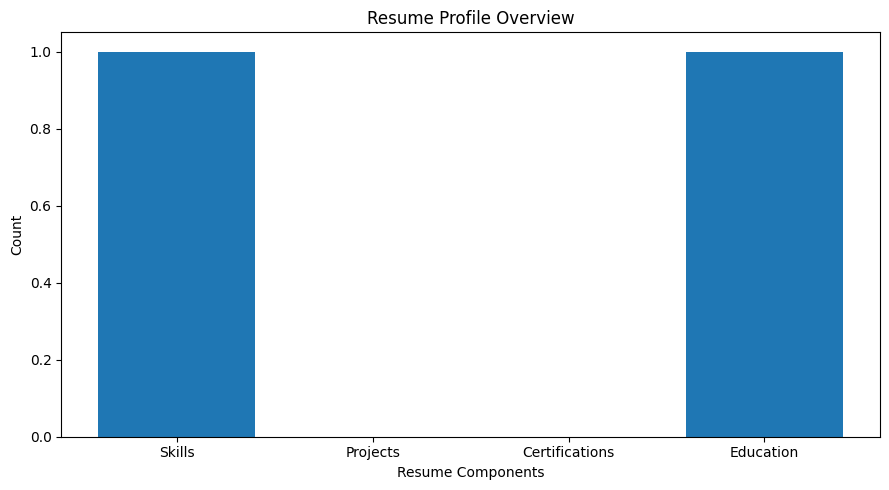

In [27]:
# Step 24: Resume Dashboard Visualization

import matplotlib.pyplot as plt

# Dashboard data
dashboard_data = {
    "Skills": len(skills),
    "Projects": len(projects),
    "Certifications": len(certifications),
    "Education": 1 if education else 0
}

# Create visualization
plt.figure(figsize=(9, 5))

plt.bar(
    dashboard_data.keys(),
    dashboard_data.values()
)

plt.title("Resume Profile Overview")
plt.xlabel("Resume Components")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

## Step 25: Project Conclusion

### Objective

Display the final completion message for the CareerCompass AI Resume Analyzer project.

### Output

- Project Completed Successfully

In [ ]:
# Step 25: Project Conclusion

print("=" * 60)
print("CAREER COMPASS AI - PROJECT CONCLUSION")
print("=" * 60)

print("\nThe Career Compass AI system successfully analyzes")
print("a candidate's resume and generates personalized career insights.")

print("\nKey outputs generated:")
print(f"1. Resume information extraction")
print(f"2. {len(skills)} technical skills identified")
print(f"3. {len(projects)} projects identified")
print(f"4. {len(certifications)} certifications identified")
print(f"5. Skill gap analysis")
print(f"6. Career recommendation: {best_career}")
print(f"7. Learning recommendations")
print(f"8. Personalized AI career roadmap")
print(f"9. Resume score: {resume_score}/100")
print(f"10. Resume dashboard visualization")

print("\nThe notebook provides the analytical foundation")
print("for the Career Compass AI Streamlit application.")

print("\nNext Step:")
print("Integrate the complete pipeline into a Streamlit")
print("web application for an interactive user experience.")


## Step 26: Batch Resume Analysis

### Objective

Analyze multiple uploaded PDF resumes or ZIP archives containing PDFs using the same core CareerCompass AI workflow. ZIP files are extracted first and every PDF inside is processed separately. For each resume, extract available candidate details, identify technical skills, assess skill gaps, calculate career-match percentages, and generate a heuristic resume completeness score.

### Output

- Candidate contact details (where detectable)
- Extracted technical skills and missing target skills
- Skill coverage percentage
- Project, certification, education, and summary indicators
- Career match scores and best-matching role
- Heuristic resume score and assessment
- Downloadable batch analysis CSV
- ZIP upload support for processing multiple PDF resumes in one upload

**Note:** Batch extraction is automated and section/keyword based. Results should be reviewed because resume layouts and headings vary. The resume score is a completeness heuristic, not a hiring prediction.


In [ ]:
# Step 26: Complete Batch Resume Analysis (PDF + ZIP supported)
# Upload either multiple PDF files OR one/more ZIP files containing PDFs.

from google.colab import files
import fitz
import re
import pandas as pd
import zipfile
import tempfile
from pathlib import Path

uploaded_batch = files.upload()

# Reuse the same skill library and career requirements used in the main analysis.
batch_target_skills = [
    "Python", "SQL", "NumPy", "Pandas", "Scikit-learn",
    "Machine Learning", "Deep Learning", "Data Preprocessing",
    "Feature Engineering", "Exploratory Data Analysis",
    "Data Visualization", "Matplotlib", "Seaborn",
    "Natural Language Processing", "TensorFlow", "PyTorch",
    "Git", "GitHub", "Streamlit"
]

batch_career_requirements = {
    "Data Scientist": ["Python", "SQL", "Pandas", "NumPy", "Scikit-learn", "Machine Learning", "Data Visualization", "Exploratory Data Analysis"],
    "Machine Learning Engineer": ["Python", "NumPy", "Pandas", "Scikit-learn", "Machine Learning", "Feature Engineering", "Git", "GitHub"],
    "AI / NLP Engineer": ["Python", "Machine Learning", "Natural Language Processing", "Deep Learning", "Scikit-learn"],
    "Data Analyst": ["Python", "SQL", "Pandas", "NumPy", "Data Visualization", "Exploratory Data Analysis"]
}


def extract_section_lines(resume_text, start_headings, stop_headings):
    lines = [line.strip() for line in resume_text.splitlines() if line.strip()]
    captured, capture = [], False
    starts = {h.upper() for h in start_headings}
    stops = {h.upper() for h in stop_headings}
    for line in lines:
        normalized = line.strip().rstrip(":").upper()
        if normalized in starts:
            capture = True
            continue
        if capture and normalized in stops:
            break
        if capture:
            captured.append(line)
    return captured


def analyze_one_resume(pdf_path):
    pdf_path = Path(pdf_path)
    with fitz.open(str(pdf_path)) as pdf:
        resume_text = "\n".join(page.get_text() for page in pdf)

    email_match = re.search(r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}", resume_text)
    phone_match = re.search(r"\+?\d[\d\s()\-]{7,}\d", resume_text)

    candidate_name = "Not Found"
    for line in resume_text.splitlines()[:15]:
        clean = line.strip()
        if (re.fullmatch(r"[A-Z][A-Z .'-]{2,}", clean)
                and clean not in {"EDUCATION", "PROJECTS", "CERTIFICATIONS", "EXPERIENCE", "SKILLS"}):
            candidate_name = clean.title()
            break

    aliases = {
        "Exploratory Data Analysis": ["Exploratory Data Analysis", "EDA"],
        "Natural Language Processing": ["Natural Language Processing", "NLP"],
        "Scikit-learn": ["Scikit-learn", "sklearn"]
    }
    detected_skills = []
    for skill in batch_target_skills:
        terms = aliases.get(skill, [skill])
        if any(re.search(r"(?<!\w)" + re.escape(term) + r"(?!\w)", resume_text, re.IGNORECASE) for term in terms):
            detected_skills.append(skill)

    project_lines = extract_section_lines(resume_text,
        ["PROJECTS", "ACADEMIC PROJECTS", "ACADEMIC & PERSONAL PROJECTS"],
        ["CERTIFICATIONS", "CERTIFICATIONS & PROFESSIONAL LEARNING", "EDUCATION", "EXPERIENCE", "INTERNSHIPS", "RESEARCH PUBLICATION", "SKILLS", "TECHNICAL SKILLS"])
    certification_lines = extract_section_lines(resume_text,
        ["CERTIFICATIONS", "CERTIFICATIONS & PROFESSIONAL LEARNING", "CERTIFICATES"],
        ["PROJECTS", "EDUCATION", "EXPERIENCE", "INTERNSHIPS", "LEADERSHIP", "TECHNICAL SKILLS", "SKILLS", "LANGUAGES"])
    education_lines = extract_section_lines(resume_text,
        ["EDUCATION", "ACADEMIC QUALIFICATIONS"],
        ["PROJECTS", "EXPERIENCE", "INTERNSHIPS", "CERTIFICATIONS", "SKILLS", "TECHNICAL SKILLS", "LEADERSHIP", "LANGUAGES"])
    summary_lines = extract_section_lines(resume_text,
        ["PROFESSIONAL SUMMARY", "SUMMARY", "PROFILE"],
        ["EDUCATION", "PROJECTS", "ACADEMIC PROJECTS", "EXPERIENCE", "INTERNSHIPS", "SKILLS", "KEY SKILLS", "TECHNICAL SKILLS", "CERTIFICATIONS"])
    summary_text = " ".join(summary_lines)

    detected_set = {s.lower() for s in detected_skills}
    missing_target = [s for s in batch_target_skills if s.lower() not in detected_set]
    skill_coverage = len(detected_skills) / len(batch_target_skills) * 100 if batch_target_skills else 0
    career_matches = {}
    for career, required in batch_career_requirements.items():
        matched = [s for s in required if s.lower() in detected_set]
        career_matches[career] = round(len(matched) / len(required) * 100, 1)
    best_career = max(career_matches, key=career_matches.get) if career_matches else "Not Available"

    skills_score = min(len(detected_skills) / 10 * 30, 30)
    projects_score = min(len(project_lines) / 3 * 25, 25)
    certifications_score = min(len(certification_lines) / 3 * 15, 15)
    education_score = 15 if education_lines else 0
    summary_score = 15 if len(summary_text.strip()) >= 50 else (8 if summary_text.strip() else 0)
    total_score = round(min(skills_score + projects_score + certifications_score + education_score + summary_score, 100), 1)
    assessment = "Excellent" if total_score >= 85 else "Strong" if total_score >= 70 else "Moderate" if total_score >= 55 else "Needs Improvement"

    return {
        "Resume": pdf_path.name,
        "Candidate Name": candidate_name,
        "Email": email_match.group(0) if email_match else "Not Found",
        "Phone": phone_match.group(0).strip() if phone_match else "Not Found",
        "Skills Found": ", ".join(detected_skills),
        "Missing Target Skills": ", ".join(missing_target),
        "Skill Coverage (%)": round(skill_coverage, 1),
        "Projects Extracted": len(project_lines),
        "Certifications Extracted": len(certification_lines),
        "Education Found": "Yes" if education_lines else "No",
        "Professional Summary Found": "Yes" if summary_text else "No",
        "Best Career Match": best_career,
        "Career Match Scores": str(career_matches),
        "Resume Score (/100)": total_score,
        "Resume Assessment": assessment,
        "Text Length": len(resume_text)
    }


# Expand ZIP archives first, then collect every PDF. This prevents a ZIP from
# being mistakenly passed to PyMuPDF as if it were a single resume.
with tempfile.TemporaryDirectory() as temp_dir:
    temp_root = Path(temp_dir)
    pdf_paths = []
    extraction_errors = []

    for uploaded_name in uploaded_batch.keys():
        uploaded_path = Path(uploaded_name)
        if uploaded_path.suffix.lower() == ".zip":
            try:
                with zipfile.ZipFile(uploaded_path, "r") as archive:
                    for member in archive.infolist():
                        member_path = Path(member.filename)
                        # Ignore folders, hidden/system files, and unsafe paths.
                        if member.is_dir() or member_path.suffix.lower() != ".pdf" or member.filename.startswith("__MACOSX/"):
                            continue
                        safe_name = member_path.name
                        destination = temp_root / f"{len(pdf_paths):03d}_{safe_name}"
                        with archive.open(member) as source, open(destination, "wb") as target:
                            target.write(source.read())
                        pdf_paths.append(destination)
            except zipfile.BadZipFile:
                extraction_errors.append(f"{uploaded_name}: invalid ZIP file")
        elif uploaded_path.suffix.lower() == ".pdf":
            pdf_paths.append(uploaded_path)
        else:
            extraction_errors.append(f"{uploaded_name}: unsupported file type (upload PDF or ZIP)")

    print(f"PDF resumes found for analysis: {len(pdf_paths)}")
    if extraction_errors:
        print("\nFiles skipped:")
        for message in extraction_errors:
            print("-", message)

    batch_results = []
    for index, pdf_path in enumerate(pdf_paths, start=1):
        print(f"Analyzing resume {index}/{len(pdf_paths)}: {pdf_path.name}")
        try:
            batch_results.append(analyze_one_resume(pdf_path))
        except Exception as error:
            batch_results.append({"Resume": pdf_path.name, "Processing Error": str(error)})

    batch_results_df = pd.DataFrame(batch_results)
    print(f"\nBATCH RESUME ANALYSIS COMPLETED: {len(batch_results_df)} PDF(s) processed")
    display(batch_results_df)

    csv_path = "careercompass_batch_resume_analysis.csv"
    batch_results_df.to_csv(csv_path, index=False)
    print(f"\nSaved: {csv_path}")
    files.download(csv_path)
